In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("") # Fill with your own path

# Graph

Columns in CSV: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


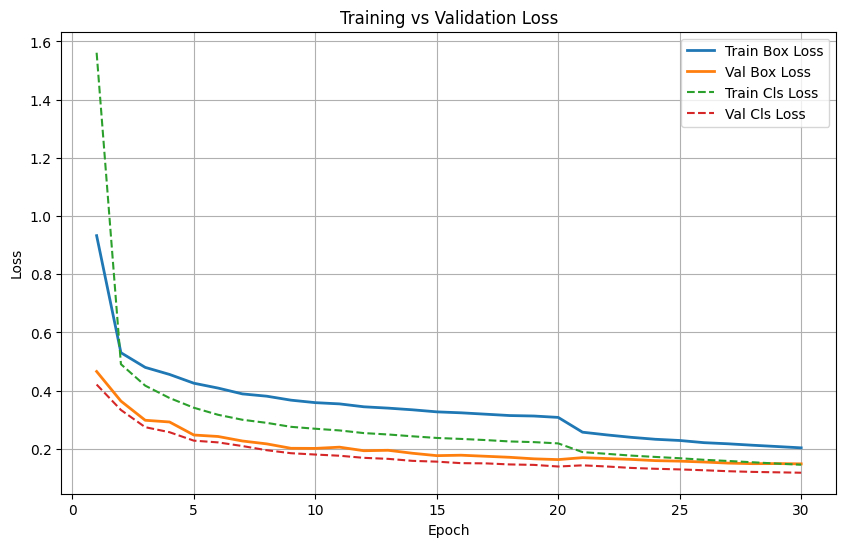

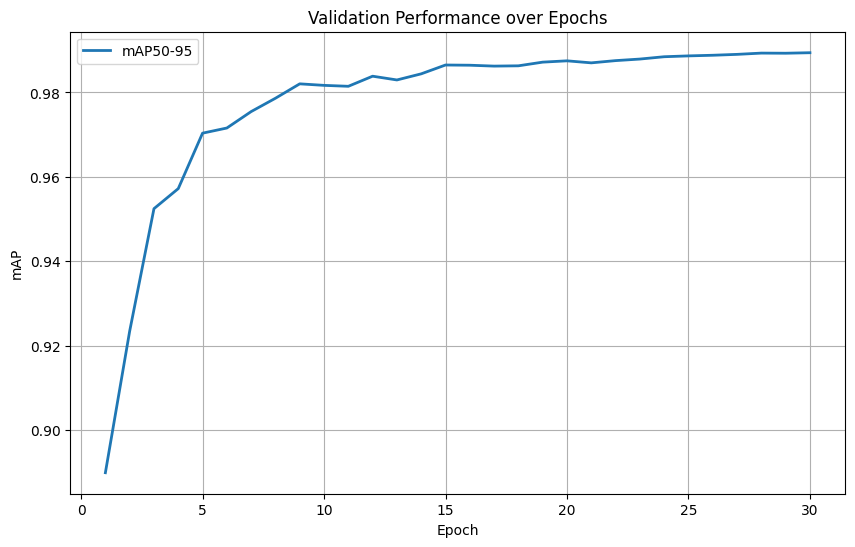

In [2]:
print("Columns in CSV:", df.columns.tolist())

plt.figure(figsize=(10, 6))
plt.plot(df['epoch'], df['train/box_loss'], label='Train Box Loss', linewidth=2)
plt.plot(df['epoch'], df['val/box_loss'], label='Val Box Loss', linewidth=2)
plt.plot(df['epoch'], df['train/cls_loss'], label='Train Cls Loss', linestyle='--')
plt.plot(df['epoch'], df['val/cls_loss'], label='Val Cls Loss', linestyle='--')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

if 'metrics/mAP50(B)' in df.columns:
    plt.figure(figsize=(10, 6))
    plt.plot(df['epoch'], df['metrics/mAP50-95(B)'], label='mAP50-95', linewidth=2)
    plt.xlabel("Epoch")
    plt.ylabel("mAP")
    plt.title("Validation Performance over Epochs")
    plt.legend()
    plt.grid(True)
    plt.show()

# Overfitting signs:
# 1. Training loss ↓ continues to decrease while validation loss ↑ starts increasing.
# 2. Training accuracy ↑ keeps improving while validation accuracy plateaus or drops.


## Detailed

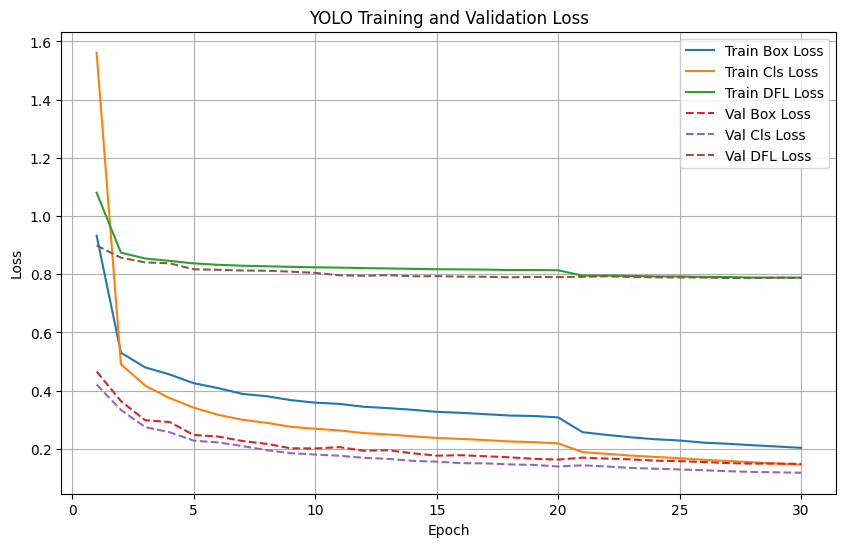

In [3]:
df['metrics/F1(B)'] = 2 * (df['metrics/precision(B)'] * df['metrics/recall(B)']) / (
    df['metrics/precision(B)'] + df['metrics/recall(B)'] + 1e-8)  # avoid div 0

plt.figure(figsize=(10,6))
plt.plot(df['epoch'], df['train/box_loss'], label='Train Box Loss')
plt.plot(df['epoch'], df['train/cls_loss'], label='Train Cls Loss')
plt.plot(df['epoch'], df['train/dfl_loss'], label='Train DFL Loss')

plt.plot(df['epoch'], df['val/box_loss'], '--', label='Val Box Loss')
plt.plot(df['epoch'], df['val/cls_loss'], '--', label='Val Cls Loss')
plt.plot(df['epoch'], df['val/dfl_loss'], '--', label='Val DFL Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLO Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


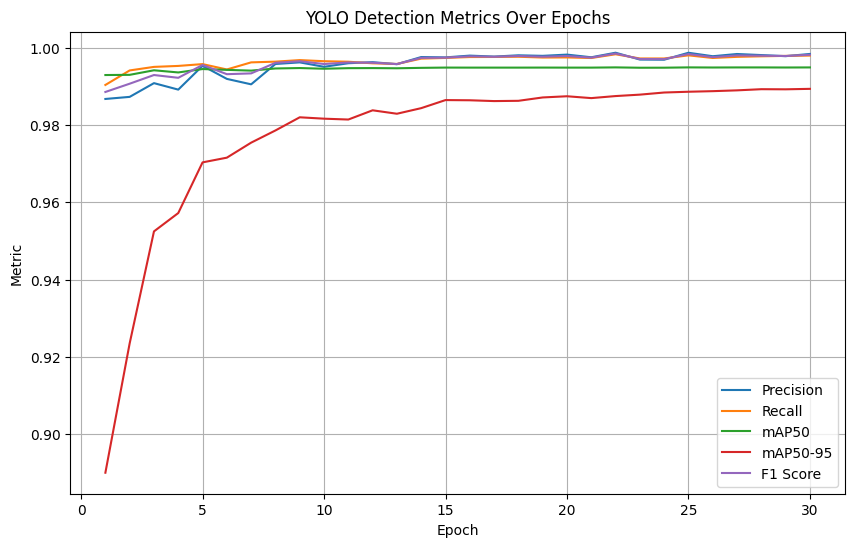

In [4]:
plt.figure(figsize=(10,6))
plt.plot(df['epoch'], df['metrics/precision(B)'], label='Precision')
plt.plot(df['epoch'], df['metrics/recall(B)'], label='Recall')
plt.plot(df['epoch'], df['metrics/mAP50(B)'], label='mAP50')
plt.plot(df['epoch'], df['metrics/mAP50-95(B)'], label='mAP50-95')
plt.plot(df['epoch'], df['metrics/F1(B)'], label='F1 Score')

plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("YOLO Detection Metrics Over Epochs")
plt.legend()
plt.grid(True)
plt.show()

# Evaluation Table

In [5]:
summary_cols = [
    'epoch', 
    'train/box_loss', 'train/cls_loss', 'train/dfl_loss',
    'val/box_loss', 'val/cls_loss', 'val/dfl_loss',
    'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'metrics/F1(B)',
    'lr/pg0', 'lr/pg1', 'lr/pg2', 'time'
]

print("Final Epoch:")
print(df[summary_cols].iloc[-1].to_frame().T)

print("\nAverage Metrics")
print(df[summary_cols].mean())

Final Epoch:
    epoch  train/box_loss  train/cls_loss  train/dfl_loss  val/box_loss  \
29   30.0         0.20341         0.14542         0.78851       0.14838   

    val/cls_loss  val/dfl_loss  metrics/precision(B)  metrics/recall(B)  \
29       0.11792       0.78727               0.99845            0.99803   

    metrics/mAP50(B)  metrics/mAP50-95(B)  metrics/F1(B)    lr/pg0    lr/pg1  \
29           0.99496              0.98941        0.99824  0.000025  0.000025   

      lr/pg2     time  
29  0.000025  7877.28  

Average Metrics
epoch                     15.500000
train/box_loss             0.342534
train/cls_loss             0.289092
train/dfl_loss             0.824117
val/box_loss               0.204510
val/cls_loss               0.178305
val/dfl_loss               0.804215
metrics/precision(B)       0.995760
metrics/recall(B)          0.996664
metrics/mAP50(B)           0.994634
metrics/mAP50-95(B)        0.977373
metrics/F1(B)              0.996210
lr/pg0                     